# Predicting NFL Quarterback Success

## Research Hypothesis
College QB decision-making, negative-play avoidance,
pocket management, and efficient rushing value predict
NFL success better than traditional passing statistics.

## Objective
Construct and evaluate NFL quarterback performance
targets, beginning with EPA per dropback.

## Initial Dataset
NFL play-by-play data from nflverse, 2023 season.

### 2.1 - Install libraries

In [2]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

### 2.2 - Load first dataset

In [3]:
pbp = nfl.load_pbp([2023]).to_pandas()
print("Dataset shape:", pbp.shape)
pbp.head()

Dataset shape: (49665, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,side_of_field,yardline_100,game_date,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,game_half,quarter_end,drive,sp,qtr,down,goal_to_go,time,yrdln,ydstogo,ydsnet,desc,play_type,yards_gained,shotgun,no_huddle,qb_dropback,qb_kneel,qb_spike,qb_scramble,pass_length,pass_location,air_yards,yards_after_catch,run_location,run_gap,field_goal_result,kick_distance,extra_point_result,two_point_conv_result,home_timeouts_remaining,away_timeouts_remaining,timeout,timeout_team,...,drive_play_id_ended,away_score,home_score,location,result,total,spread_line,total_line,div_game,roof,surface,temp,wind,home_coach,away_coach,stadium_id,game_stadium,aborted_play,success,passer,passer_jersey_number,rusher,rusher_jersey_number,receiver,receiver_jersey_number,pass,rush,first_down,special,play,passer_id,rusher_id,receiver_id,name,jersey_number,id,fantasy_player_name,fantasy_player_id,fantasy,fantasy_id,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,NaN,NaN,NaN,NaN,NaN,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,NaN,0.0,1.0,NaN,0,15:00,ARI 35,0.0,NaN,GAME,NaN,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,NaN,NaN,...,NaN,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,ARI,35.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,NaN,0,15:00,ARI 35,0.0,26.0,5-M.Prater kicks 65 yards from ARI 35 to end z...,kickoff,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,75.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,1.0,0,15:00,WAS 25,10.0,26.0,(15:00) (Shotgun) 8-B.Robinson right tackle to...,run,3.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,right,tackle,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,B.Robinson,8.0,NaN,NaN,0.0,1.0,0.0,0.0,1.0,NaN,00-0037746,NaN,B.Robinson,8.0,00-0037746,B.Robinson,00-0037746,B.Robinson,00-0037746,0.0,1.0,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,72.0,2023-09-10,870.0,1770.0,3570.0,Half1,0.0,1.0,0.0,1.0,2.0,0,14:30,WAS 28,7.0,26.0,(14:30) (Shotgun) 14-S.Howell pass short right...,pass,6.0,1.0,0.0,1.0,0.0,0.0,0.0,short,right,6.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,S.Howell,14.0,NaN,NaN,J.Dotson,1.0,1.0,0.0,0.0,0.0,1.0,00-0037077,NaN,00-0037741,S.Howell,14.0,00-0037077,J.Dotson,00-0037741,J.Dotson,00-0037741,0.0,1.0,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,66.0,2023-09-10,835.0,1735.0,3535.0,Half1,0.0,1.0,0.0,1.0,3.0,0,13:55,WAS 34,1.0,26.0,(13:55) 23-C.Rodriguez left guard to WAS 36 fo...,run,2.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,left,guard,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,NaN,NaN,C.Rodriguez,23.0,NaN,NaN,0.0,1.0,1.0,0.0,1.0,NaN,00-0038611,NaN,C.Rodriguez,23.0,00-0038611,C.Rodriguez,00-0038611,C.Rodriguez,00-0038611,0.0,1.0,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


### 2.3 - Inspect available variables

In [5]:
pbp.columns

Index(['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team',
       'season_type', 'week', 'posteam', 'posteam_type', 'defteam',
       ...
       'out_of_bounds', 'home_opening_kickoff', 'qb_epa', 'xyac_epa',
       'xyac_mean_yardage', 'xyac_median_yardage', 'xyac_success', 'xyac_fd',
       'xpass', 'pass_oe'],
      dtype='str', length=372)

In [9]:
qb_columns = [
    "season",
    "week",
    "passer_player_name",
    "passer_player_id",
    "rusher_player_name",
    "rusher_player_id",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

available = [col for col in qb_columns if col in pbp.columns]

print("Available columns:")
print(available)

pbp[available].head(20)

Available columns:
['season', 'week', 'passer_player_name', 'passer_player_id', 'rusher_player_name', 'rusher_player_id', 'play_type', 'qb_dropback', 'sack', 'qb_scramble', 'air_yards', 'yards_after_catch', 'epa']


,season,week,passer_player_name,passer_player_id,rusher_player_name,rusher_player_id,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
0,2023,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.000000
1,2023,1,NaN,NaN,NaN,NaN,kickoff,0.0,0.0,0.0,NaN,NaN,0.000000
2,2023,1,NaN,NaN,B.Robinson,00-0037746,run,0.0,0.0,0.0,NaN,NaN,-0.336103
3,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,6.0,0.0,0.703308
4,2023,1,NaN,NaN,C.Rodriguez,00-0038611,run,0.0,0.0,0.0,NaN,NaN,0.469799
5,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719


### 2.4 Filter the dataset

In [10]:
# Select only plays involving a quarterback dropback
qb_plays = pbp.loc[pbp["qb_dropback"] == 1].copy()

print("Original dataset:", pbp.shape)
print("QB dropback dataset:", qb_plays.shape)

# Inspect relevant columns
columns = [
    "passer_player_name",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

qb_plays[columns].head(15)

Original dataset: (49665, 372)
QB dropback dataset: (21819, 372)


,passer_player_name,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
3,S.Howell,pass,1.0,0.0,0.0,6.0,0.0,0.703308
5,S.Howell,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,S.Howell,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,S.Howell,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,S.Howell,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,S.Howell,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719
13,J.Dobbs,pass,1.0,0.0,0.0,6.0,0.0,1.648779
14,J.Dobbs,pass,1.0,0.0,0.0,8.0,NaN,-0.579366
15,J.Dobbs,pass,1.0,0.0,0.0,-4.0,1.0,-1.215581
19,S.Howell,pass,1.0,0.0,0.0,4.0,2.0,0.484837


### 2.5 - Examine missing values

In [11]:
qb_plays[columns].isna().sum()

passer_player_name    1096
play_type                0
qb_dropback              0
sack                     0
qb_scramble              0
air_yards             2635
yards_after_catch     9392
epa                      0
dtype: int64

### 2.6 - Verify the dropback categories

In [12]:
print("Total QB dropbacks:", len(qb_plays))
print("Sacks:", (qb_plays["sack"] == 1).sum())
print("Scrambles:", (qb_plays["qb_scramble"] == 1).sum())
print("Neither sack nor scramble:",
    (
        (qb_plays["sack"] == 0)
        & (qb_plays["qb_scramble"] == 0)
    ).sum()
)

Total QB dropbacks: 21819
Sacks: 1459
Scrambles: 1096
Neither sack nor scramble: 19264


### 3.1 Investigate the missing passer names

In [13]:
# Examine dropbacks where passer name is missing
missing_passers = qb_plays[qb_plays["passer_player_name"].isna()]

missing_passers[
    [
        "passer_player_name",
        "rusher_player_name",
        "play_type",
        "sack",
        "qb_scramble",
        "epa"
    ]
].head(15)

,passer_player_name,rusher_player_name,play_type,sack,qb_scramble,epa
50,NaN,S.Howell,run,0.0,1.0,-0.045260
134,NaN,S.Howell,run,0.0,1.0,2.813332
193,NaN,J.Allen,run,0.0,1.0,2.350573
225,NaN,J.Allen,run,0.0,1.0,0.926030
246,NaN,J.Allen,run,0.0,1.0,-0.083463
302,NaN,Z.Wilson,run,0.0,1.0,0.562715
319,NaN,J.Allen,run,0.0,1.0,0.037364
422,NaN,B.Young,run,0.0,1.0,1.168277
508,NaN,B.Young,run,0.0,1.0,-1.537297
522,NaN,D.Watson,run,0.0,1.0,2.242414


In [14]:
# Check whether all missing passer names are scrambles
missing_passers["qb_scramble"].value_counts(dropna=False)

qb_scramble
1.0    1096
Name: count, dtype: int64

### 3.2 - Construct unified QB identifier

In [17]:
# Create a unified QB name column
qb_plays["qb_name"] = qb_plays[
    "passer_player_name"
].fillna(qb_plays["rusher_player_name"])

# Create a unified QB ID column
qb_plays["qb_id"] = qb_plays[
    "passer_player_id"
].fillna(qb_plays["rusher_player_id"])

# Verify that every dropback has a QB
print("Missing QB names:", qb_plays["qb_name"].isna().sum())
print("Missing QB IDs:", qb_plays["qb_id"].isna().sum())

Missing QB names: 0
Missing QB IDs: 0


### 4 - Calculate QB EPA per dropback

In [20]:
qb_stats = (
    qb_plays.groupby(["qb_id", "qb_name"], as_index=False).agg(
        dropbacks=("epa", "size"),
        total_epa=("epa", "sum"),
        sacks=("sack", "sum"),
        scrambles=("qb_scramble", "sum")
    )
)

# Calculate performance and negative-play metrics
qb_stats["epa_per_dropback"] = (
    qb_stats["total_epa"] / qb_stats["dropbacks"]
)

qb_stats["sack_rate"] = (
    qb_stats["sacks"] / qb_stats["dropbacks"]
)

qb_stats["scramble_rate"] = (
    qb_stats["scrambles"] / qb_stats["dropbacks"]
)

qb_stats.head()

,qb_id,qb_name,dropbacks,total_epa,sacks,scrambles,epa_per_dropback,sack_rate,scramble_rate
0,00-0023459,A.Rodgers,2,-2.031960,1.0,0.0,-1.015980,0.500000,0.000000
1,00-0026158,J.Flacco,265,-27.508541,12.0,2.0,-0.103806,0.045283,0.007547
2,00-0026498,M.Stafford,603,70.822678,32.0,14.0,0.117451,0.053068,0.023217
3,00-0026625,B.Hoyer,43,-8.780773,1.0,0.0,-0.204204,0.023256,0.000000
4,00-0027114,T.Morstead,1,2.670900,0.0,0.0,2.670900,0.000000,0.000000


### 5 - Rank the Quarterbacks

In [21]:
qualified_qbs = qb_stats[
    qb_stats["dropbacks"] >= 200
].copy()

qb_rankings = (
    qualified_qbs.sort_values("epa_per_dropback", ascending=False)
)

qb_rankings[
    [
        "qb_name",
        "dropbacks",
        "epa_per_dropback",
        "sack_rate",
        "scramble_rate"
    ]
].head(20)

,qb_name,dropbacks,epa_per_dropback,sack_rate,scramble_rate
100,B.Purdy,604,0.292405,0.052980,0.039735
29,D.Prescott,728,0.188657,0.059066,0.045330
55,J.Allen,732,0.174355,0.035519,0.077869
74,J.Love,690,0.155223,0.043478,0.036232
72,T.Tagovailoa,649,0.143452,0.047766,0.029276
40,P.Mahomes,839,0.123978,0.038141,0.075089
30,J.Goff,762,0.123121,0.048556,0.010499
59,J.Browning,284,0.119502,0.084507,0.056338
2,M.Stafford,603,0.117451,0.053068,0.023217
119,C.Stroud,613,0.113349,0.061990,0.040783


### 6.1 - Relationship between Sack Rate and EPA

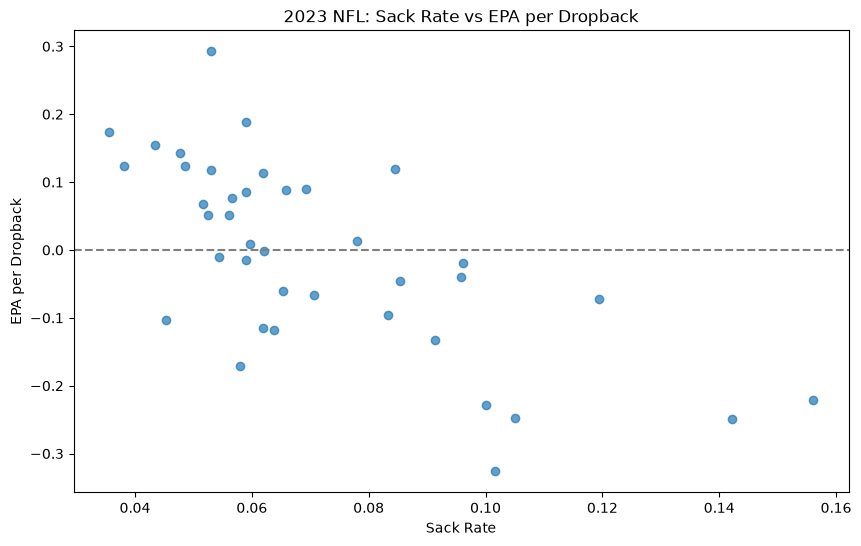

In [22]:
plt.figure(figsize=(10, 6))
plt.scatter(
    qualified_qbs["sack_rate"],
    qualified_qbs["epa_per_dropback"],
    alpha=0.7
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Sack Rate")
plt.ylabel("EPA per Dropback")
plt.title("2023 NFL: Sack Rate vs EPA per Dropback")

plt.show()

### 6.2 - Calculate the correlation of sack rate and epa per dropback

In [ ]:
sack_corr = qualified_qbs["sack_rate"].corr(qualified_qbs["epa_per_dropback"])
print(f"Correlation: {sack_corr:.3f}")

Correlation: -0.685


### 6.3 - Calculate the correlation of scramble rate and epa per dropback

In [24]:
scramble_corr = qualified_qbs["scramble_rate"].corr(qualified_qbs["epa_per_dropback"])
print(f"Scramble correlation: {scramble_corr:.3f}")

Scramble correlation: -0.118


### 7 - Compare the EPA of different dropback outcomes

In [26]:
qb_plays["dropback_type"] = np.select(
    [qb_plays["sack"] == 1, qb_plays["qb_scramble"] == 1],
    ["Sack", "Scramble"], default="Other dropback"
)

epa_by_type = (
    qb_plays.groupby("dropback_type").agg(
        plays=("epa", "size"),
        mean_epa=("epa", "mean"),
        median_epa=("epa", "median")
    ).reset_index()
)

epa_by_type

,dropback_type,plays,mean_epa,median_epa
0,Other dropback,19264,0.116872,-0.109539
1,Sack,1459,-1.797979,-1.557734
2,Scramble,1096,0.446733,0.250660
